    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

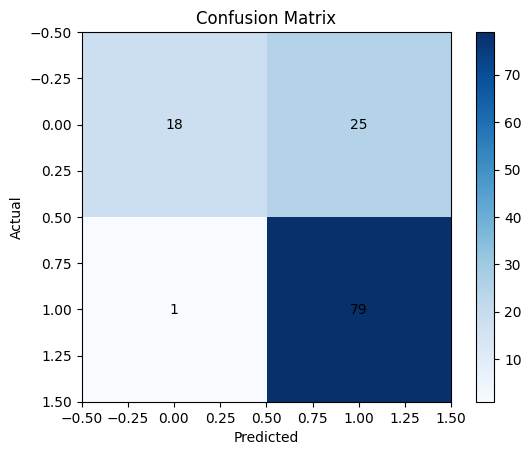

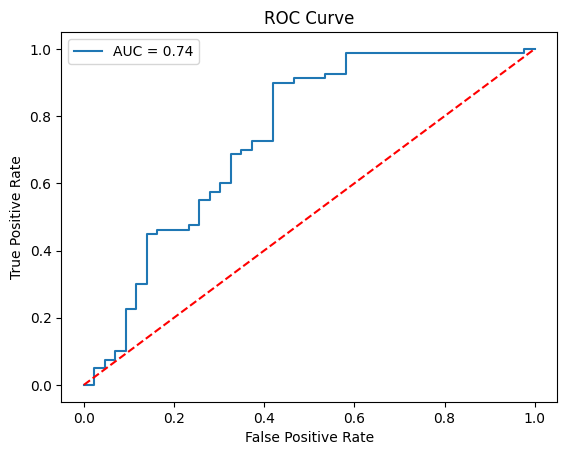


AUC Score: 0.7395348837209302


In [ ]:
# Import Libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc
)
# 1. Load Dataset
df = pd.read_csv("loanData.csv")

print(df.head(5))
print(df.info())

# 2. Data Preprocessing
# Fill missing values
df = df.fillna(df.mode().iloc[0])
# Convert categorical data into numbers
encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = encoder.fit_transform(df[col])
# Remove Loan_ID

df.drop("Loan_ID", axis=1, inplace=True)

# Features and Target
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

# 3. Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# 4. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Train Logistic Regression Model
model = LogisticRegression()

model.fit(
    X_train,
    y_train
)
# 6. Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred
)
print("\nConfusion Matrix:")
print(cm)
# Metrics

print("\nAccuracy:",
      accuracy_score(y_test,y_pred))

print("Precision:",
      precision_score(y_test,y_pred))

print("Recall:",
      recall_score(y_test,y_pred))

print("F1 Score:",
      f1_score(y_test,y_pred))

# Display Confusion Matrix

plt.imshow(cm,cmap="Blues")

plt.title("Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i,j],
                 ha="center",
                 va="center")

plt.show()
# 8. ROC Curve and AUC
fpr, tpr, threshold = roc_curve(
    y_test,
    y_prob
)

roc_auc = auc(
    fpr,
    tpr
)

plt.plot(
    fpr,
    tpr,
    label="AUC = %.2f" % roc_auc
)
plt.plot(
    [0,1],
    [0,1],
    'r--'
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()
print("\nAUC Score:", roc_auc)



